**1. Instalação e importação das bibliotecas**

*Usaremos pandas e scikit-learn para manipulação e vetorização dos textos, TensorFlow/Keras para construir o autoencoder e matplotlib para os gráficos.*

In [1]:
%pip -q install tensorflow scikit-learn pandas matplotlib requests

import io
import time
import zipfile
import random
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
    average_precision_score, classification_report
)
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Dispositivo(s):", tf.config.list_physical_devices())

TensorFlow: 2.21.0
Dispositivo(s): [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


**2. Carregamento do conjunto de dados**

*Será utilizada a SMS Spam Collection, disponibilizada pelo UCI Machine Learning Repository. A base reúne 5.574 mensagens SMS em inglês, classificadas como ham (legítima) ou spam.*

*Fonte oficial: https://archive.ics.uci.edu/dataset/228/sms*

In [2]:
URL_DATASET = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
resposta = requests.get(URL_DATASET, timeout=60)
resposta.raise_for_status()

with zipfile.ZipFile(io.BytesIO(resposta.content)) as arquivo_zip:
    arquivos_dados = [nome for nome in arquivo_zip.namelist() if nome.endswith("SMSSpamCollection")]
    if not arquivos_dados:
        raise FileNotFoundError("O arquivo SMSSpamCollection não foi encontrado dentro do ZIP da UCI.")
    conteudo = arquivo_zip.read(arquivos_dados[0]).decode("utf-8", errors="replace")

registros = []
for linha in conteudo.splitlines():
    partes = linha.split("\t", 1)
    if len(partes) == 2:
        rotulo, mensagem = partes
        rotulo = rotulo.strip()
        mensagem = mensagem.strip()
        if rotulo in {"ham", "spam"} and mensagem:
            registros.append((rotulo, mensagem))

df = pd.DataFrame(registros, columns=["label", "text"])
if df.empty:
    raise ValueError("Nenhuma mensagem válida foi carregada. Verifique o arquivo baixado.")

print(f"Registros carregados: {len(df):,}")
print("Primeiras linhas:")
display(df.head())

Registros carregados: 5,574
Primeiras linhas:


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


**3. Inspeção e preparação dos dados**

*A preparação remove mensagens vazias e duplicatas exatas. Caso o mesmo texto apareça associado a rótulos diferentes, essas ocorrências ambíguas são retiradas para evitar que o mesmo conteúdo apareça em divisões diferentes com respostas conflitantes.*

*A distribuição das classes é analisada antes da divisão. A base é desbalanceada: há muito mais mensagens legítimas do que spam. Por isso, a acurácia sozinha não será suficiente para avaliar o desempenho.*

Registros inicialmente carregados: 5,574
Textos ambíguos removidos: 0
Duplicatas exatas removidas: 414
Total após preparação: 5,160

Distribuição das classes:


,Quantidade
label,
Normal (ham),4518
Spam,642


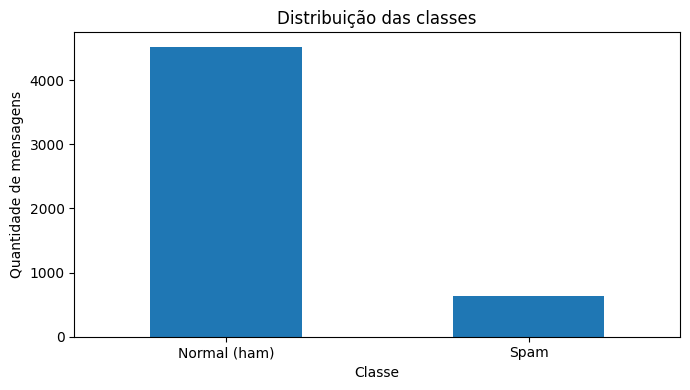

In [3]:
quantidade_inicial = len(df)
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"].ne("")].dropna(subset=["label", "text"]).copy()

conflitos = df.groupby("text")["label"].nunique()
textos_ambiguos = conflitos[conflitos > 1].index
df = df[~df["text"].isin(textos_ambiguos)].copy()
quantidade_antes_deduplicacao = len(df)
df = df.drop_duplicates(subset=["text"], keep="first").reset_index(drop=True)

print(f"Registros inicialmente carregados: {quantidade_inicial:,}")
print(f"Textos ambíguos removidos: {len(textos_ambiguos):,}")
print(f"Duplicatas exatas removidas: {quantidade_antes_deduplicacao - len(df):,}")
print(f"Total após preparação: {len(df):,}")
print("\nDistribuição das classes:")
contagem_classes = df["label"].value_counts().reindex(["ham", "spam"], fill_value=0)
display(contagem_classes.rename(index={"ham": "Normal (ham)", "spam": "Spam"}).to_frame("Quantidade"))

ax = contagem_classes.rename(index={"ham": "Normal (ham)", "spam": "Spam"}).plot(
    kind="bar", figsize=(7, 4), title="Distribuição das classes"
)
ax.set_xlabel("Classe")
ax.set_ylabel("Quantidade de mensagens")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**4. Separação em treino, validação e teste**

*A separação será estratificada para preservar aproximadamente a proporção de ham e spam em cada subconjunto:*

*- 70% treino: ajuste dos modelos;*

*- 15% validação: acompanhamento do treinamento e definição do limite de anomalia;*

*- 15% teste: avaliação final, utilizado somente depois das escolhas dos modelos.*

*O vocabulário TF-IDF da regressão logística e o vocabulário binário do autoencoder serão ajustados exclusivamente com o conjunto de treino. A validação e o teste receberão apenas as transformações desses vocabulários. Isso evita o vazamento de dados.*

In [4]:
X = df["text"]
y = df["label"]

X_treino, X_temporario, y_treino, y_temporario = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_validacao, X_teste, y_validacao, y_teste = train_test_split(
    X_temporario, y_temporario, test_size=0.50,
    random_state=SEED, stratify=y_temporario
)

resumo_divisao = pd.DataFrame({
    "Treino": y_treino.value_counts(normalize=True),
    "Validação": y_validacao.value_counts(normalize=True),
    "Teste": y_teste.value_counts(normalize=True),
}).fillna(0).reindex(["ham", "spam"])
print(f"Treino: {len(X_treino):,} ({len(X_treino)/len(df):.1%})")
print(f"Validação: {len(X_validacao):,} ({len(X_validacao)/len(df):.1%})")
print(f"Teste: {len(X_teste):,} ({len(X_teste)/len(df):.1%})")
print("\nProporção de classes por subconjunto:")
display(resumo_divisao)

Treino: 3,612 (70.0%)
Validação: 774 (15.0%)
Teste: 774 (15.0%)

Proporção de classes por subconjunto:


,Treino,Validação,Teste
label,,,
ham,0.875692,0.874677,0.875969
spam,0.124308,0.125323,0.124031


**5. Representação numérica dos textos: TF-IDF e Bag-of-Words**

*Redes neurais recebem números, não frases diretamente. Neste projeto, serão utilizadas duas formas de representação numérica.*

*A regressão logística utilizará TF-IDF (Term Frequency–Inverse Document Frequency), que atribui pesos aos termos de acordo com sua importância relativa na mensagem.*

*O autoencoder utilizará Bag-of-Words binário, no qual cada posição representa um termo do vocabulário e indica se ele aparece (1) ou não aparece (0) na mensagem.*

*Essa segunda representação permite que o autoencoder aprenda a reconstruir a presença ou ausência dos termos nas mensagens legítimas.*

*Ambos os vocabulários serão ajustados exclusivamente com os dados de treino, evitando vazamento de informações.*

In [5]:

# Representação TF-IDF para a baseline.
vetorizador = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    max_features=1500,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    norm="l2",
    dtype=np.float32
)

X_treino_tfidf = vetorizador.fit_transform(X_treino)
X_validacao_tfidf = vetorizador.transform(X_validacao)
X_teste_tfidf = vetorizador.transform(X_teste)


# Representação Bag-of-Words binária para o autoencoder.
vetorizador_bow = CountVectorizer(
    lowercase=True,
    strip_accents="unicode",
    binary=True,
    max_features=3000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    dtype=np.float32
)

X_treino_bow = vetorizador_bow.fit_transform(X_treino)
X_validacao_bow = vetorizador_bow.transform(X_validacao)
X_teste_bow = vetorizador_bow.transform(X_teste)


print("Características TF-IDF:", X_treino_tfidf.shape[1])
print("Características Bag-of-Words:", X_treino_bow.shape[1])

print("\nFormato dos vetores Bag-of-Words:")
print("Treino:", X_treino_bow.shape)
print("Validação:", X_validacao_bow.shape)
print("Teste:", X_teste_bow.shape)

indice_exemplo = 0
termos_bow = vetorizador_bow.get_feature_names_out()

print("\nMensagem de exemplo:")
print(X_treino.iloc[indice_exemplo])

print("\nTermos presentes na mensagem:")
print(termos_bow[X_treino_bow[indice_exemplo].indices][:15])


Características TF-IDF: 1500
Características Bag-of-Words: 3000

Formato dos vetores Bag-of-Words:
Treino: (3612, 3000)
Validação: (774, 3000)
Teste: (774, 3000)

Mensagem de exemplo:
Me i'm not workin. Once i get job...

Termos presentes na mensagem:
['me' 'not' 'workin' 'once' 'get' 'job' 'me not']


**6. Baseline: regressão logística**

*A baseline será uma regressão logística treinada com os vetores TF-IDF e os rótulos do conjunto de treino. Ela é uma referência clássica e mais simples do que a rede neural utilizada neste projeto.*

*Como há menos mensagens spam, será usado class_weight="balanced" para compensar o desbalanceamento durante o ajuste. A baseline é supervisionada: aprende diretamente com os rótulos ham e spam.*

In [6]:
baseline = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=SEED,
)
baseline.fit(X_treino_tfidf, y_treino)

previsoes_baseline = baseline.predict(X_teste_tfidf)
probabilidades_baseline = baseline.predict_proba(X_teste_tfidf)[:, list(baseline.classes_).index("spam")]
print("Baseline treinada.")

Baseline treinada.


**7. Arquitetura do autoencoder**

*O autoencoder possui duas partes:*

*- Encoder: comprime a representação binária da mensagem em uma representação menor, chamada gargalo ou espaço latente.*

*- Decoder: tenta reconstruir a presença dos termos da mensagem original a partir dessa representação comprimida.*

*O treinamento será realizado somente com mensagens ham do conjunto de treino. A hipótese é que a rede aprenda padrões comuns de mensagens legítimas e apresente maior erro ao reconstruir mensagens diferentes desses padrões.*

*O autoencoder utiliza uma representação Bag-of-Words binária e uma função de perda Binary Cross-Entropy (BCE) ponderada. Essa função atribui maior importância aos termos presentes na mensagem, reduzindo a influência das posições iguais a zero e favorecendo o aprendizado dos padrões das mensagens legítimas.*

*A arquitetura será composta pelas camadas 256 → 128 → 64 → 128 → 256, com representação latente de 64 dimensões.*

*Como os rótulos são utilizados para selecionar as mensagens legítimas, trata-se de uma abordagem one-class ou semi-supervisionada.*

In [7]:

# Converte as matrizes binárias em matrizes densas para entrada no Keras.
X_treino_denso = X_treino_bow.toarray().astype(np.float32)
X_validacao_denso = X_validacao_bow.toarray().astype(np.float32)
X_teste_denso = X_teste_bow.toarray().astype(np.float32)

y_treino_array = y_treino.to_numpy()
y_validacao_array = y_validacao.to_numpy()
y_teste_array = y_teste.to_numpy()

mascara_ham_treino = y_treino_array == "ham"
mascara_ham_validacao = y_validacao_array == "ham"

X_treino_ham = X_treino_denso[mascara_ham_treino]
X_validacao_ham = X_validacao_denso[mascara_ham_validacao]

if len(X_treino_ham) == 0 or len(X_validacao_ham) == 0:
    raise ValueError("Não há mensagens ham suficientes para treinar/calibrar o autoencoder.")

numero_caracteristicas = X_treino_denso.shape[1]

# Peso menor para termos ausentes.
PESO_TERMO_AUSENTE = 0.005


# Função de perda Binary Cross-Entropy ponderada.
def bce_ponderada(y_true, y_pred):
    epsilon = tf.keras.backend.epsilon()

    y_pred = tf.clip_by_value(
        y_pred,
        epsilon,
        1.0 - epsilon
    )

    bce = -(
        y_true * tf.math.log(y_pred)
        + (1.0 - y_true) * tf.math.log(1.0 - y_pred)
    )

    pesos = tf.where(
        y_true > 0.0,
        1.0,
        PESO_TERMO_AUSENTE
    )

    erro_por_amostra = tf.reduce_sum(
        pesos * bce,
        axis=1
    ) / tf.reduce_sum(pesos, axis=1)

    return erro_por_amostra


# Camada de entrada.
entrada = Input(
    shape=(numero_caracteristicas,),
    name="presenca_termos"
)


# Encoder.
x = Dense(256, activation="relu", name="encoder_256")(entrada)
x = Dense(128, activation="relu", name="encoder_128")(x)

latente = Dense(
    64,
    activation="relu",
    name="representacao_latente"
)(x)


# Decoder.
x = Dense(128, activation="relu", name="decoder_128")(latente)
x = Dense(256, activation="relu", name="decoder_256")(x)

saida = Dense(
    numero_caracteristicas,
    activation="sigmoid",
    name="reconstrucao"
)(x)


# Modelo completo.
autoencoder = Model(
    entrada,
    saida,
    name="autoencoder_spam"
)

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss=bce_ponderada
)

autoencoder.summary()


Model: "autoencoder_spam"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ presenca_termos (InputLayer)    │ (None, 3000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_256 (Dense)             │ (None, 256)            │       768,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_128 (Dense)             │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ representacao_latente (Dense)   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_128 (Dense)             │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_256 (Dense)             │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstrucao (Dense)            │ (None, 3000)           │       771,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,621,752 (6.19 MB)

 Trainable params: 1,621,752 (6.19 MB)

 Non-trainable params: 0 (0.00 B)

**8. Treinamento do autoencoder**

*Configurações principais:*

*- Até 60 épocas;*

*- Lote (batch size) de 32;*

*- Otimizador Adam, com taxa de aprendizado 0,0005;*

*- Perda Binary Cross-Entropy ponderada;*

*- Peso 1 para termos presentes e 0,005 para termos ausentes;*

*- ReLU nas camadas ocultas;*

*- Sigmoid na camada de saída;*

*- Early Stopping com paciência de 7 épocas, restaurando os melhores pesos.*

*A rede será treinada apenas com mensagens ham. A saída sigmoid reconstrói a presença dos termos e não representa diretamente a probabilidade de spam.*

Epoch 1/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 36s 152ms/step - loss: 0.5513 - val_loss: 0.4505
Epoch 2/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 13s 133ms/step - loss: 0.4578 - val_loss: 0.4356
Epoch 3/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - loss: 0.4467 - val_loss: 0.4275
Epoch 4/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 11s 101ms/step - loss: 0.4191 - val_loss: 0.3983
Epoch 5/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - loss: 0.3934 - val_loss: 0.3895
Epoch 6/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - loss: 0.3692 - val_loss: 0.3741
Epoch 7/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.3416 - val_loss: 0.3821
Epoch 8/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 0.3183 - val_loss: 0.3807
Epoch 9/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.2999 - val_loss: 0.3759
Epoch 10/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.2800 - val_loss: 0.3627
Epoch 11/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.2607 - val_loss: 0.3645
Epoch 12/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - los

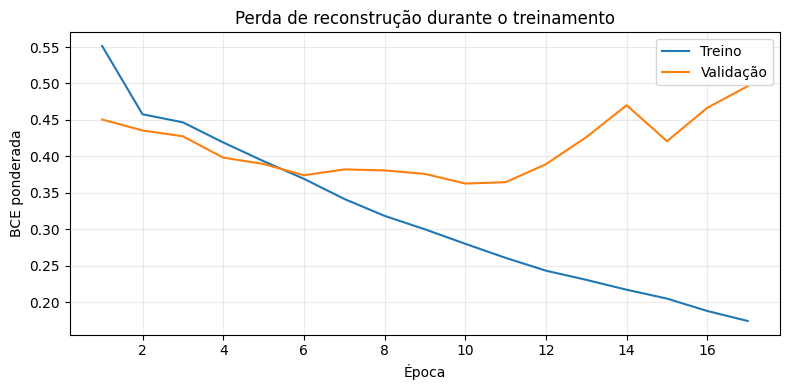

In [8]:

parada_antecipada = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

inicio_treinamento = time.time()

historico = autoencoder.fit(
    X_treino_ham,
    X_treino_ham,
    validation_data=(X_validacao_ham, X_validacao_ham),
    epochs=60,
    batch_size=32,
    shuffle=True,
    callbacks=[parada_antecipada],
    verbose=1
)

tempo_treinamento = time.time() - inicio_treinamento
epocas_executadas = len(historico.history["loss"])

print(f"\nÉpocas executadas: {epocas_executadas}")
print(f"Tempo de treinamento: {tempo_treinamento:.2f} segundos")


plt.figure(figsize=(8, 4))

plt.plot(
    range(1, epocas_executadas + 1),
    historico.history["loss"],
    label="Treino"
)

plt.plot(
    range(1, epocas_executadas + 1),
    historico.history["val_loss"],
    label="Validação"
)

plt.title("Perda de reconstrução durante o treinamento")
plt.xlabel("Época")
plt.ylabel("BCE ponderada")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


**9. Definição do limite entre normal e anomalia**

*Para cada mensagem, calculamos o erro de reconstrução utilizando Binary Cross-Entropy ponderada entre os termos originais e os reconstruídos.*

*Os termos presentes recebem peso 1, enquanto os ausentes recebem peso 0,005. Dessa forma, o erro considera com maior importância os termos que realmente aparecem na mensagem.*

*Mensagens com erro maior que o limite serão sinalizadas como spam.*

*O limite será o percentil 95 dos erros de reconstrução das mensagens ham da validação. O conjunto de teste permanecerá separado e será utilizado somente na avaliação final.*

*Também será apresentado um gráfico comparando a distribuição dos erros de mensagens ham e spam na validação. Os exemplos spam serão utilizados apenas para diagnóstico visual, sem participar da definição do limite.*

Limite de anomalia (percentil 95): 0.58169652
Mediana do erro ham: 0.37128737
Mediana do erro spam: 1.43385740


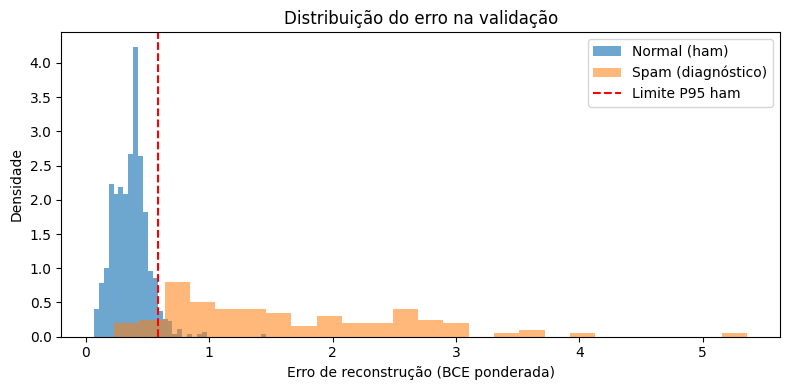

In [9]:

def calcular_erro_reconstrucao(matriz):

    reconstruida = autoencoder.predict(
        matriz,
        verbose=0
    )

    epsilon = tf.keras.backend.epsilon()

    reconstruida = np.clip(
        reconstruida,
        epsilon,
        1.0 - epsilon
    )

    bce = -(
        matriz * np.log(reconstruida)
        + (1.0 - matriz) * np.log(1.0 - reconstruida)
    )

    pesos = np.where(
        matriz > 0.0,
        1.0,
        PESO_TERMO_AUSENTE
    )

    erros = (
        np.sum(pesos * bce, axis=1)
        / np.sum(pesos, axis=1)
    )

    return erros


# Erro das mensagens normais na validação.
erros_validacao_ham = calcular_erro_reconstrucao(
    X_validacao_ham
)


# Definição do limite utilizando somente ham.
limite_anomalia = float(
    np.percentile(erros_validacao_ham, 95)
)

print(
    f"Limite de anomalia (percentil 95): {limite_anomalia:.8f}"
)

print(
    f"Mediana do erro ham: {np.median(erros_validacao_ham):.8f}"
)


# Diagnóstico das mensagens spam na validação.
erros_validacao_spam = calcular_erro_reconstrucao(
    X_validacao_denso[y_validacao_array == "spam"]
)

print(
    f"Mediana do erro spam: {np.median(erros_validacao_spam):.8f}"
)


# Gráfico comparativo.
plt.figure(figsize=(8, 4))

plt.hist(
    erros_validacao_ham,
    bins=35,
    alpha=0.65,
    density=True,
    label="Normal (ham)"
)

plt.hist(
    erros_validacao_spam,
    bins=25,
    alpha=0.55,
    density=True,
    label="Spam (diagnóstico)"
)

plt.axvline(
    limite_anomalia,
    color="red",
    linestyle="--",
    label="Limite P95 ham"
)

plt.xlabel("Erro de reconstrução (BCE ponderada)")
plt.ylabel("Densidade")
plt.title("Distribuição do erro na validação")
plt.legend()
plt.tight_layout()
plt.show()


**10. Avaliação final no conjunto de teste**

*As métricas principais serão precisão, recall e F1-score da classe spam, além da acurácia, área sob a curva ROC e Average Precision (área resumida da curva precisão-recall).*

*O F1-score equilibra precisão e recall; o recall mostra quantos spams reais foram encontrados.*

*A avaliação final utiliza o conjunto de teste, que não foi usado para treinar a rede, ajustar a baseline, escolher o limite ou ajustar os vocabulários.*

In [10]:
# Autoencoder: erro alto -> spam (1); erro baixo -> normal (0)
erros_teste = calcular_erro_reconstrucao(X_teste_denso)
previsoes_autoencoder_binarias = (erros_teste > limite_anomalia).astype(int)

# Rótulos binários: spam=1 e ham=0
y_teste_binario = (y_teste_array == "spam").astype(int)
previsoes_baseline_binarias = (previsoes_baseline == "spam").astype(int)


def calcular_metricas(nome, y_real, y_previsto, scores):
    return {
        "Modelo": nome,
        "Acurácia": accuracy_score(y_real, y_previsto),
        "Precisão (spam)": precision_score(y_real, y_previsto, zero_division=0),
        "Recall (spam)": recall_score(y_real, y_previsto, zero_division=0),
        "F1-score (spam)": f1_score(y_real, y_previsto, zero_division=0),
        "ROC-AUC": roc_auc_score(y_real, scores),
        "Average Precision": average_precision_score(y_real, scores),
    }

resultados = pd.DataFrame([
    calcular_metricas("Baseline — Regressão Logística", y_teste_binario, previsoes_baseline_binarias, probabilidades_baseline),
    calcular_metricas("Autoencoder — Detecção de anomalias", y_teste_binario, previsoes_autoencoder_binarias, erros_teste),
]).set_index("Modelo")

print("Métricas no conjunto de teste:")
display(resultados.style.format("{:.4f}"))

print("\nRelatório de classificação — Autoencoder:")
print(classification_report(
    y_teste_binario,
    previsoes_autoencoder_binarias,
    labels=[0, 1],
    target_names=["Normal (ham)", "Spam"],
    zero_division=0,
))

Métricas no conjunto de teste:


,Acurácia,Precisão (spam),Recall (spam),F1-score (spam),ROC-AUC,Average Precision
Modelo,,,,,,
Baseline — Regressão Logística,0.9819,0.9100,0.9479,0.9286,0.9970,0.9834
Autoencoder — Detecção de anomalias,0.9341,0.6667,0.9375,0.7792,0.9831,0.9446



Relatório de classificação — Autoencoder:
              precision    recall  f1-score   support

Normal (ham)       0.99      0.93      0.96       678
        Spam       0.67      0.94      0.78        96

    accuracy                           0.93       774
   macro avg       0.83      0.94      0.87       774
weighted avg       0.95      0.93      0.94       774



**11. Matrizes de confusão e análise dos erros**

*Na matriz de confusão:*

*- Falso positivo: uma mensagem legítima foi marcada como spam;*

*- Falso negativo: uma mensagem spam foi classificada como normal.*

*Os dois erros importam. Muitos falsos positivos podem fazer o usuário perder mensagens legítimas; muitos falsos negativos permitem a passagem de mensagens indesejadas.*

*Os exemplos de acertos e erros serão utilizados para analisar o comportamento do autoencoder.*

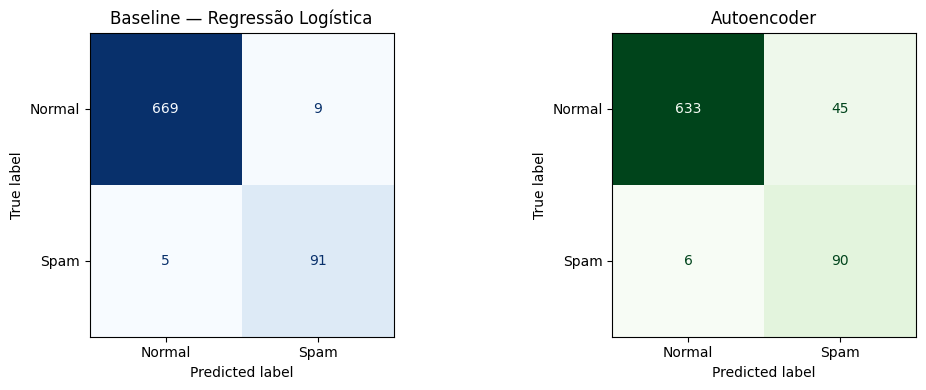

Exemplos de falsos positivos (normal classificado como spam):


,mensagem,esperado,previsto_autoencoder,erro_reconstrucao
7,I've got it down to a tea. not sure which flavour,ham,spam,0.674802
33,"Aight, text me tonight and we'll see what's up",ham,spam,0.632101
53,I havent add ü yet right..,ham,spam,0.630543


Exemplos de falsos negativos (spam classificado como normal):


,mensagem,esperado,previsto_autoencoder,erro_reconstrucao
276,Call 09095350301 and send our girls into eroti...,spam,ham,0.542471
450,Can U get 2 phone NOW? I wanna chat 2 set up m...,spam,ham,0.450984
543,You have 1 new message. Please call 08718738034.,spam,ham,0.471907


In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_teste_binario, previsoes_baseline_binarias,
    display_labels=["Normal", "Spam"], cmap="Blues", ax=eixos[0], colorbar=False
)
eixos[0].set_title("Baseline — Regressão Logística")
ConfusionMatrixDisplay.from_predictions(
    y_teste_binario, previsoes_autoencoder_binarias,
    display_labels=["Normal", "Spam"], cmap="Greens", ax=eixos[1], colorbar=False
)
eixos[1].set_title("Autoencoder")
plt.tight_layout()
plt.show()

analise_erros = pd.DataFrame({
    "mensagem": X_teste.to_numpy(),
    "esperado": y_teste_array,
    "previsto_autoencoder": np.where(previsoes_autoencoder_binarias == 1, "spam", "ham"),
    "erro_reconstrucao": erros_teste,
})

falsos_positivos = analise_erros[
    (analise_erros["esperado"] == "ham") & (analise_erros["previsto_autoencoder"] == "spam")
]
falsos_negativos = analise_erros[
    (analise_erros["esperado"] == "spam") & (analise_erros["previsto_autoencoder"] == "ham")
]

print("Exemplos de falsos positivos (normal classificado como spam):")
display(falsos_positivos.head(3))
print("Exemplos de falsos negativos (spam classificado como normal):")
display(falsos_negativos.head(3))

In [12]:

# Exemplos completos para o slide 13.

pd.set_option("display.max_colwidth", None)


# Mensagens normais classificadas corretamente.
acertos_ham = analise_erros[
    (analise_erros["esperado"] == "ham") &
    (analise_erros["previsto_autoencoder"] == "ham")
]

print("EXEMPLO DE ACERTO — MENSAGEM NORMAL")

if not acertos_ham.empty:
    exemplo = acertos_ham.iloc[0]

    print("Mensagem:", exemplo["mensagem"])
    print("Esperado:", exemplo["esperado"])
    print("Previsto:", exemplo["previsto_autoencoder"])
    print(f"Erro: {exemplo['erro_reconstrucao']:.8f}")

else:
    print("Não houve acertos de mensagens normais.")


# Mensagens spam classificadas corretamente.
acertos_spam = analise_erros[
    (analise_erros["esperado"] == "spam") &
    (analise_erros["previsto_autoencoder"] == "spam")
]

print("\nEXEMPLO DE ACERTO — SPAM")

if not acertos_spam.empty:
    exemplo = acertos_spam.iloc[0]

    print("Mensagem:", exemplo["mensagem"])
    print("Esperado:", exemplo["esperado"])
    print("Previsto:", exemplo["previsto_autoencoder"])
    print(f"Erro: {exemplo['erro_reconstrucao']:.8f}")

else:
    print("Não houve acertos de mensagens spam.")


# Falsos negativos.
print("\nEXEMPLO DE FALSO NEGATIVO")

if not falsos_negativos.empty:
    exemplo = falsos_negativos.iloc[0]

    print("Mensagem:", exemplo["mensagem"])
    print("Esperado:", exemplo["esperado"])
    print("Previsto:", exemplo["previsto_autoencoder"])
    print(f"Erro: {exemplo['erro_reconstrucao']:.8f}")

else:
    print("Não houve falsos negativos nesta execução.")


# Falsos positivos.
print("\nEXEMPLO DE FALSO POSITIVO")

if not falsos_positivos.empty:
    exemplo = falsos_positivos.iloc[0]

    print("Mensagem:", exemplo["mensagem"])
    print("Esperado:", exemplo["esperado"])
    print("Previsto:", exemplo["previsto_autoencoder"])
    print(f"Erro: {exemplo['erro_reconstrucao']:.8f}")

else:
    print("Não houve falsos positivos nesta execução.")


EXEMPLO DE ACERTO — MENSAGEM NORMAL
Mensagem: Sez, hows u & de arab boy? Hope u r all good give my love 2 evry1 love ya eshxxxxxxxxxxx
Esperado: ham
Previsto: ham
Erro: 0.41295141

EXEMPLO DE ACERTO — SPAM
Mensagem: WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
Esperado: spam
Previsto: spam
Erro: 2.13195375

EXEMPLO DE FALSO NEGATIVO
Mensagem: Call 09095350301 and send our girls into erotic ecstacy. Just 60p/min. To stop texts call 08712460324 (nat rate)
Esperado: spam
Previsto: ham
Erro: 0.54247104

EXEMPLO DE FALSO POSITIVO
Mensagem: I've got it down to a tea. not sure which flavour
Esperado: ham
Previsto: spam
Erro: 0.67480151


**12. Comparação e interpretação**

*A comparação entre a regressão logística e o autoencoder considera principalmente o F1-score, a precisão e o recall da classe spam, permitindo avaliar a capacidade de cada modelo de identificar mensagens indesejadas.*

*A regressão logística utiliza os rótulos das duas classes durante o treinamento, enquanto o autoencoder é treinado apenas com mensagens legítimas e identifica possíveis anomalias por meio do erro de reconstrução.*

*Essa comparação permite analisar o desempenho das duas abordagens, identificando suas vantagens e limitações na detecção de spam.*

In [13]:
comparacao = resultados[["Precisão (spam)", "Recall (spam)", "F1-score (spam)", "Average Precision"]].copy()
display(comparacao.style.format("{:.4f}"))

f1_baseline = float(resultados.loc["Baseline — Regressão Logística", "F1-score (spam)"])
f1_autoencoder = float(resultados.loc["Autoencoder — Detecção de anomalias", "F1-score (spam)"])
print(f"Diferença de F1 (autoencoder - baseline): {f1_autoencoder - f1_baseline:+.4f}")
if f1_autoencoder > f1_baseline:
    print("Neste teste, o autoencoder apresentou F1 maior que a baseline.")
elif f1_autoencoder < f1_baseline:
    print("Neste teste, a baseline apresentou F1 maior que o autoencoder.")
else:
    print("Neste teste, os dois modelos tiveram o mesmo F1-score.")

,Precisão (spam),Recall (spam),F1-score (spam),Average Precision
Modelo,,,,
Baseline — Regressão Logística,0.9100,0.9479,0.9286,0.9834
Autoencoder — Detecção de anomalias,0.6667,0.9375,0.7792,0.9446


Diferença de F1 (autoencoder - baseline): -0.1494
Neste teste, a baseline apresentou F1 maior que o autoencoder.


**13. Teste com uma nova mensagem**

*A função abaixo transforma uma nova mensagem utilizando o vetorizador Bag-of-Words binário e calcula seu erro de reconstrução.*

*O resultado será comparado com o limite de anomalia definido na validação. Mensagens com erro maior que o limite serão sinalizadas como suspeitas de spam.*

*O erro de reconstrução não representa uma probabilidade de spam.*

*A base utilizada no treinamento contém mensagens em inglês. Por isso, os exemplos da demonstração também serão apresentados nesse idioma.*

In [14]:

def analisar_mensagem(mensagem):

    if not isinstance(mensagem, str) or not mensagem.strip():
        raise ValueError("Digite uma mensagem de texto não vazia.")

    vetor = vetorizador_bow.transform(
        [mensagem]
    ).toarray().astype(np.float32)

    erro = float(
        calcular_erro_reconstrucao(vetor)[0]
    )

    classe = (
        "SPAM (suspeita)"
        if erro > limite_anomalia
        else "NORMAL (ham)"
    )

    return {
        "mensagem": mensagem,
        "classificacao": classe,
        "erro_reconstrucao": erro,
        "limite": limite_anomalia,
        "observacao": (
            "Nenhum termo reconhecido no vocabulário; classificação pouco confiável."
            if not np.any(vetor)
            else "O erro de reconstrução não representa uma probabilidade."
        )
    }


# Exemplos em inglês, pois a base de treinamento contém mensagens em inglês.
exemplos = [
    "Are we still meeting for lunch tomorrow?",
    "Congratulations! You have won a free prize. Claim now!"
]

for exemplo in exemplos:
    display(analisar_mensagem(exemplo))


{'mensagem': 'Are we still meeting for lunch tomorrow?',
 'classificacao': 'NORMAL (ham)',
 'erro_reconstrucao': 0.31886732822092034,
 'limite': 0.581696522715213,
 'observacao': 'O erro de reconstrução não representa uma probabilidade.'}

{'mensagem': 'Congratulations! You have won a free prize. Claim now!',
 'classificacao': 'SPAM (suspeita)',
 'erro_reconstrucao': 3.3435507627995524,
 'limite': 0.581696522715213,
 'observacao': 'O erro de reconstrução não representa uma probabilidade.'}

In [15]:
# Demonstração interativa: digite uma mensagem em inglês na caixa de entrada do Colab.
nova_mensagem = input("Digite uma mensagem em inglês para analisar: ")
resultado_nova_mensagem = analisar_mensagem(nova_mensagem)
print("\nResultado:")
print("Classificação:", resultado_nova_mensagem["classificacao"])
print("Erro de reconstrução:", f"{resultado_nova_mensagem['erro_reconstrucao']:.8f}")
print("Limite utilizado:", f"{resultado_nova_mensagem['limite']:.8f}")
print("Observação:", resultado_nova_mensagem["observacao"])

Digite uma mensagem em inglês para analisar: WINNER!

Resultado:
Classificação: SPAM (suspeita)
Erro de reconstrução: 1.07751383
Limite utilizado: 0.58169652
Observação: O erro de reconstrução não representa uma probabilidade.


**14. Resumo dos valores para a apresentação**

*Esta seção reúne os principais valores gerados durante a execução do notebook, incluindo quantidade de mensagens, divisão dos dados, características utilizadas, épocas executadas, tempo de treinamento, limite de reconstrução e métricas dos modelos.*

In [16]:

print("RESUMO PARA OS SLIDES")
print("---------------------")

print(f"Mensagens após preparação: {len(df)}")

print(f"Treino: {len(X_treino)}")
print(f"Validação: {len(X_validacao)}")
print(f"Teste: {len(X_teste)}")

print(f"\nCaracterísticas TF-IDF (baseline): {X_treino_tfidf.shape[1]}")
print(f"Características Bag-of-Words (autoencoder): {numero_caracteristicas}")

print("\nArquitetura: 256 → 128 → 64 → 128 → 256")
print("Função de perda: Binary Cross-Entropy ponderada")
print("Otimizador: Adam")
print("Taxa de aprendizado: 0.0005")
print("Tamanho do lote: 32")

print(f"\nÉpocas executadas: {epocas_executadas}")
print(f"Tempo de treinamento (segundos): {tempo_treinamento:.2f}")
print(f"Limite de reconstrução: {limite_anomalia:.8f}")

print("\nMétricas:")
display(resultados.style.format("{:.4f}"))

print("\nMatriz de confusão — Autoencoder:")

matriz_autoencoder = confusion_matrix(
    y_teste_binario,
    previsoes_autoencoder_binarias,
    labels=[0, 1]
)

vn, fp, fn, vp = matriz_autoencoder.ravel()

print(f"Verdadeiros negativos: {vn}")
print(f"Falsos positivos: {fp}")
print(f"Falsos negativos: {fn}")
print(f"Verdadeiros positivos: {vp}")


RESUMO PARA OS SLIDES
---------------------
Mensagens após preparação: 5160
Treino: 3612
Validação: 774
Teste: 774

Características TF-IDF (baseline): 1500
Características Bag-of-Words (autoencoder): 3000

Arquitetura: 256 → 128 → 64 → 128 → 256
Função de perda: Binary Cross-Entropy ponderada
Otimizador: Adam
Taxa de aprendizado: 0.0005
Tamanho do lote: 32

Épocas executadas: 17
Tempo de treinamento (segundos): 126.45
Limite de reconstrução: 0.58169652

Métricas:


,Acurácia,Precisão (spam),Recall (spam),F1-score (spam),ROC-AUC,Average Precision
Modelo,,,,,,
Baseline — Regressão Logística,0.9819,0.9100,0.9479,0.9286,0.9970,0.9834
Autoencoder — Detecção de anomalias,0.9341,0.6667,0.9375,0.7792,0.9831,0.9446



Matriz de confusão — Autoencoder:
Verdadeiros negativos: 633
Falsos positivos: 45
Falsos negativos: 6
Verdadeiros positivos: 90


**15. Limitações e cuidados**

*A coleção contém mensagens em inglês e reflete fontes e hábitos de SMS de seu período de coleta; não representa necessariamente spam atual ou mensagens em português.*

*A baseline utiliza TF-IDF, enquanto o autoencoder utiliza Bag-of-Words binário. Ambas são representações simples e não compreendem plenamente o contexto, a intenção ou a sequência das palavras.*

*A BCE ponderada procura reduzir o problema causado pela grande quantidade de posições vazias nos vetores, mas não garante que todas as mensagens de spam sejam identificadas corretamente.*

*Uma mensagem legítima incomum pode apresentar erro alto e ser classificada incorretamente; um spam com padrões semelhantes aos de mensagens legítimas pode não ser detectado.*

*O limite de 95% é uma escolha de calibração, não uma garantia de segurança.*

*Mensagens podem conter dados pessoais. Em uma aplicação real, o tratamento deve respeitar a privacidade, o consentimento e as regras de proteção de dados.*

*O protótipo não deve bloquear mensagens automaticamente sem revisão e testes mais amplos.*

**Declaração de uso de inteligência artificial**

*A inteligência artificial generativa foi utilizada como apoio à organização do projeto, à explicação dos conceitos e à elaboração inicial do notebook e da documentação.*

**Referências**

*UCI MACHINE LEARNING REPOSITORY. SMS Spam Collection. Disponível em: https://archive.ics.uci.edu/dataset/228/sms.*

*ALMEIDA, T. A.; GÓMEZ HIDALGO, J. M.; YAMAKAMI, A. Contributions to the study of SMS Spam Filtering: New Collection and Results. Proceedings of the 2011 ACM Symposium on Document Engineering, 2011.*

*PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, v. 12, p. 2825–2830, 2011.*

*ABADI, M. et al. TensorFlow: A System for Large-Scale Machine Learning. 2016.*